# 2. Fourier differentiation and the FFT

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/02_fourier_differentiation_and_fft.ipynb)

*Companion to Chapters 2 and 3 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Notebook 1 reached the spectral differentiation matrix as the limit of finite difference
formulas of ever higher order. This notebook reaches the same matrix by a second road, which is
the one that generalizes: **interpolate the data by a smooth function, then differentiate the
interpolant**. On a periodic grid the interpolant is a sum of sines and cosines, and that opens
the door to the fast Fourier transform, which replaces the dense matrix by an algorithm whose
cost grows only a little faster than the number of grid points.

You will see:

- why a grid can only represent a limited range of wavenumbers (aliasing and the Nyquist limit)
- the sinc function and its periodic cousin, and the differentiation matrix they produce
- differentiation as multiplication by $ik$ in Fourier space, with NumPy's FFT
- what to do with the highest wavenumber on the grid, and what goes wrong otherwise
- interpolation between the grid points by zero-padding

**Worked examples:** the piston of notebook 1 by FFT, and the acceleration of the same piston
from noisy position measurements.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 2.1 What a grid can and cannot see

The periodic grid of notebook 1 has $N$ points $x_j = jh$, $j = 0, \dots, N-1$, with
$h = 2\pi/N$ and $N$ even. The natural building blocks for periodic functions are the waves
$e^{ikx}$ with integer wavenumber $k$.

**By hand.** Sample two waves whose wavenumbers differ by $N$:

$$e^{i(k+N)x_j} = e^{ikx_j}\,e^{iNjh} = e^{ikx_j}\,e^{2\pi i j} = e^{ikx_j} .$$

They take **the same values at every grid point**. The grid cannot tell them apart. This is
**aliasing**: a high wavenumber puts on the mask (the alias) of a low one.

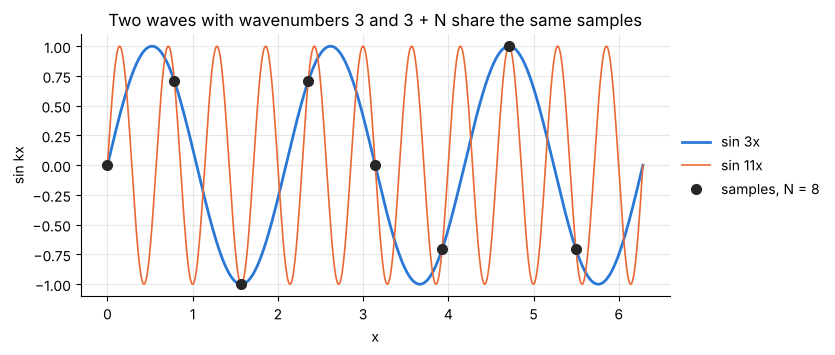

In [2]:
N = 8
x = 2 * np.pi * np.arange(N) / N
fine = np.linspace(0, 2 * np.pi, 800)

fig, ax = plt.subplots(figsize=(7.6, 3.4))
ax.plot(fine, np.sin(3 * fine), label="sin 3x")
ax.plot(fine, np.sin(11 * fine), lw=1.2, label="sin 11x")
ax.plot(x, np.sin(3 * x), "o", color="0.15", ms=7, label="samples, N = 8")
ax.set(xlabel="x", ylabel="sin kx", title="Two waves with wavenumbers 3 and 3 + N share the same samples")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
assert np.allclose(np.sin(3 * x), np.sin(11 * x));

So on an $N$-point grid there are only $N$ distinguishable wavenumbers. The sensible choice is
the $N$ smallest in magnitude,

$$k = -\tfrac N2 + 1,\ \dots,\ -1,\ 0,\ 1,\ \dots,\ \tfrac N2 ,$$

and every other wavenumber is an alias of one of these. The largest, $k = N/2 = \pi/h$, is the
**Nyquist wavenumber**. Its wavelength is $2h$: **two grid points per wavelength** is the
finest oscillation a grid can carry. On the grid that wave is the sawtooth
$e^{i(N/2)x_j} = (-1)^j$, and it is its own mirror image, because $k = -N/2$ gives the same
samples. That ambiguity returns in 2.4.

For an engineer the rule reads: a feature of wavelength $\lambda$ needs $h < \lambda/2$ to be
seen at all, and whatever the grid cannot see does not vanish. It is folded back onto a lower
wavenumber and contaminates the result there.

## 2.2 An unbounded grid: the sinc function

Start with the simplest data, on a grid $x_j = jh$ that extends to infinity in both directions:
a **unit spike**, equal to 1 at $x_0 = 0$ and 0 at every other grid point. Infinitely many
functions pass through these values. By 2.1 the grid carries no information about wavenumbers
above $\pi/h$, so choose the interpolant that contains none: the **band-limited interpolant**.

**By hand.** The spike contains every wavenumber in equal amount. Keeping the band
$|k| \le \pi/h$ gives

$$S_h(x) = \frac{h}{2\pi}\int_{-\pi/h}^{\pi/h} e^{ikx}\,dk = \frac{\sin(\pi x/h)}{\pi x/h} ,$$

the **sinc function**. It equals 1 at $x = 0$ and 0 at every other grid point, as it must.
Differentiate and evaluate at the grid points $x_n = nh$, where $\sin(\pi x/h) = 0$ and
$\cos(\pi x/h) = (-1)^n$:

$$S_h'(x_n) = \frac{(-1)^n}{nh}\quad (n \ne 0),\qquad S_h'(0) = 0 .$$

General data are a sum of shifted spikes, $u_m$ times a spike at $x_m$, so the interpolant is
$p(x) = \sum_m u_m S_h(x - x_m)$ and its derivative at $x_j$ is, with $k$ now counting grid
points away from $x_j$ as in notebook 1,

$$p'(x_j) = \sum_m u_m\,S_h'(x_j - x_m) = \frac1h\sum_{k=1}^{\infty}\frac{(-1)^{k+1}}{k}\,(u_{j+k} - u_{j-k}) .$$

These are exactly the infinite-order finite difference weights $\alpha_k = (-1)^{k+1}/k$ that
section 1.4 of notebook 1 found as a limit. Raising the order of a finite difference formula
without bound and differentiating the band-limited interpolant are the same thing.

**Verify** the derivative formula numerically. A convenient independent tool is the
**complex-step derivative**: for a function that accepts complex arguments,
$f'(x) \approx \operatorname{Im} f(x + i\varepsilon)/\varepsilon$. No subtraction of nearly
equal numbers is involved, so $\varepsilon$ can be tiny and the result is accurate to rounding.

In [3]:
def sinc(x, h):
    """Band-limited interpolant of a unit spike on an unbounded grid of spacing h."""
    return np.sinc(x / h)                       # np.sinc(t) is sin(πt)/(πt), with the value 1 at t = 0

def complex_step(f, x, eps=1e-30):
    """Derivative of f at the real points x, from one evaluation at x + iε."""
    return np.imag(f(np.asarray(x) + 1j * eps)) / eps

h = 0.25
k = np.arange(-8, 9)
slopes = complex_step(lambda z: sinc(z, h), k * h)
expected = np.zeros(len(k))
expected[k != 0] = (-1.0) ** k[k != 0] / (k[k != 0] * h)
assert np.abs(slopes - expected).max() < 1e-12

# the weight of u_{j+k} is S'(-kh); times h it must be the notebook 1 limit (-1)^(k+1)/k
print("k               :", k[9:14])
print("h S'(-kh)       :", np.round(h * complex_step(lambda z: sinc(z, h), -k[9:14] * h), 4))
print("(-1)^(k+1) / k  :", np.round((-1.0) ** (k[9:14] + 1) / k[9:14], 4))

k               : [1 2 3 4 5]
h S'(-kh)       : [ 1.     -0.5     0.3333 -0.25    0.2   ]
(-1)^(k+1) / k  : [ 1.     -0.5     0.3333 -0.25    0.2   ]


## 2.3 The periodic grid: the periodic sinc function

On the periodic grid the same idea applies with one change: only the integer wavenumbers
$-N/2, \dots, N/2$ are available, so the integral becomes a sum.

**By hand.** The band-limited interpolant of the periodic unit spike is the sum of all the
available waves with equal weights, where the two ends $k = \pm N/2$, which are the same wave
on the grid, share one weight between them:

$$S_N(x) = \frac1N\Big[\tfrac12 e^{-i(N/2)x} + \sum_{k=-N/2+1}^{N/2-1} e^{ikx} + \tfrac12 e^{i(N/2)x}\Big]
= \frac{\sin(\pi x/h)}{(2\pi/h)\tan(x/2)} .$$

The closed form comes from summing the geometric series. This is the **periodic sinc
function**. Near $x = 0$, where $\tan(x/2) \approx x/2$, it is the ordinary sinc. Differentiating
and using $\sin(\pi x_n/h) = 0$, $\cos(\pi x_n/h) = (-1)^n$ again:

$$S_N'(x_n) = \tfrac12\,(-1)^n\cot\frac{nh}{2}\quad (n \ne 0),\qquad S_N'(0) = 0 .$$

As before the interpolant of general data is $p(x) = \sum_j u_j S_N(x - x_j)$, so the derivative
at the grid points is $\mathbf{w} = D\mathbf{u}$ with

$$D_{ij} = S_N'(x_i - x_j) = \tfrac12\,(-1)^{i-j}\cot\frac{x_i - x_j}{2}\quad (i \ne j),\qquad D_{ii} = 0 .$$

This is the spectral differentiation matrix of notebook 1, entry for entry.

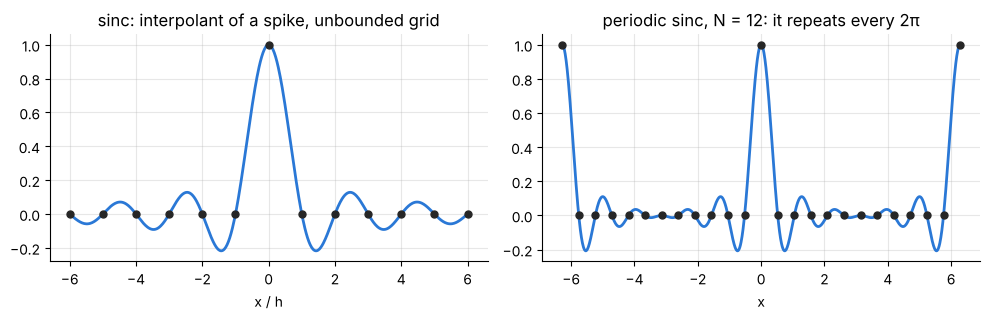

In [4]:
def periodic_sinc(x, N):
    """Band-limited interpolant of a unit spike on the periodic grid of N points (N even)."""
    h = 2 * np.pi / N
    x = np.asarray(x)
    tangent = np.tan(x / 2)
    at_spike = tangent == 0                                    # x = 0, ±2π, ...: the formula reads 0/0, the value is 1
    return np.where(at_spike, 1.0, np.sin(np.pi * x / h) / (2 * np.pi / h * np.where(at_spike, 1.0, tangent)))

def fourier_diff_matrix(N):
    """First-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]          # i - j
    D = np.zeros((N, N))
    off = k != 0
    D[off] = 0.5 * (-1.0) ** k[off] / np.tan(k[off] * h / 2)
    return D

N = 12
h = 2 * np.pi / N
x = 2 * np.pi * np.arange(N) / N

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
wide = np.linspace(-6 * h, 6 * h, 600)
axes[0].plot(wide / h, sinc(wide, h))
axes[0].plot(np.arange(-6, 7), sinc(np.arange(-6, 7) * h, h), "o", color="0.15", ms=5)
axes[0].set(xlabel="x / h", title="sinc: interpolant of a spike, unbounded grid")
around = np.linspace(-2 * np.pi, 2 * np.pi, 1200)
axes[1].plot(around, periodic_sinc(around, N))
axes[1].plot(np.arange(-N, N + 1) * h, periodic_sinc(np.arange(-N, N + 1) * h, N), "o", color="0.15", ms=5)
axes[1].set(xlabel="x", title=f"periodic sinc, N = {N}: it repeats every 2π")
fig.tight_layout()

**Verify** three things: the closed form equals the sum of waves it came from, its slopes at the
grid points are the cotangent formula, and the matrix assembled from those slopes (computed by
the complex step, with no formula for the derivative typed in) is `fourier_diff_matrix(N)`.

In [5]:
rng = np.random.default_rng(0)
points = rng.uniform(0, 2 * np.pi, 50)
wave_sum = (1 + 2 * sum(np.cos(k * points) for k in range(1, N // 2)) + np.cos(N / 2 * points)) / N
assert np.abs(periodic_sinc(points, N) - wave_sum).max() < 1e-12

k = np.arange(1, N)
assert np.abs(complex_step(lambda z: periodic_sinc(z, N), k * h) - 0.5 * (-1.0) ** k / np.tan(k * h / 2)).max() < 1e-12

D_from_interpolant = complex_step(lambda z: periodic_sinc(z, N), x[:, None] - x[None, :])
assert np.abs(D_from_interpolant - fourier_diff_matrix(N)).max() < 1e-12
print(f"largest difference between the two matrices: {np.abs(D_from_interpolant - fourier_diff_matrix(N)).max():.1e}")

largest difference between the two matrices: 4.9e-15


Two derivations, one matrix. The interpolation view is the one to keep, because it does not
depend on the grid being periodic or equally spaced: notebook 5 uses the same two steps with a
polynomial interpolant on a bounded interval.

## 2.4 The discrete Fourier transform

The interpolant is a sum of waves, and differentiating a wave is easy:
$\dfrac{d}{dx}e^{ikx} = ik\,e^{ikx}$. So instead of multiplying by a matrix one can

1. find the amplitude of each wave in the data: $\hat v_k = \sum_{j=0}^{N-1} v_j\,e^{-ikx_j}$;
2. multiply each amplitude by $ik$ (by $(ik)^m$ for the $m$-th derivative);
3. add the waves up again: $w_j = \dfrac1N\sum_k (ik)\,\hat v_k\,e^{ikx_j}$.

Step 1 is the **discrete Fourier transform** (DFT) and step 3 its inverse. `np.fft.fft` and
`np.fft.ifft` compute them with exactly these sign and scaling conventions. The one thing to
learn is the order in which the wavenumbers are stored: zero first, then the positive ones,
then the negative ones. `np.fft.fftfreq(N, 1/N)` returns that list.

In [6]:
print("wavenumber order for N = 8:", np.fft.fftfreq(8, 1 / 8).astype(int))

N = 16
x = 2 * np.pi * np.arange(N) / N
v_hat = np.fft.fft(3 + 2 * np.cos(2 * x) + np.sin(5 * x))
print("non-zero amplitudes divided by N:")
for k, amplitude in zip(np.fft.fftfreq(N, 1 / N), np.round(v_hat / N, 12) + 0):
    if abs(amplitude) > 0:
        print(f"   k = {int(k):+d}:   {amplitude.real:.1f} {'-' if amplitude.imag < 0 else '+'} {abs(amplitude.imag):.1f}i")

wavenumber order for N = 8: [ 0  1  2  3 -4 -3 -2 -1]
non-zero amplitudes divided by N:
   k = +0:   3.0 + 0.0i
   k = +2:   1.0 + 0.0i
   k = +5:   0.0 - 0.5i
   k = -5:   0.0 + 0.5i
   k = -2:   1.0 + 0.0i


The transform has found the mean value 3 at $k = 0$, the cosine as two equal amplitudes of 1 at
$k = \pm2$, and the sine as $\mp\tfrac12 i$ at $k = \pm5$, since
$\sin 5x = (e^{5ix} - e^{-5ix})/2i$. Note that `fftfreq` lists the Nyquist wavenumber as
$-N/2$, not $+N/2$.

**Verify** the conventions with Parseval's identity,
$\sum_j |v_j|^2 = \frac1N\sum_k |\hat v_k|^2$: the energy of a signal is the same whether it is
counted point by point or wave by wave.

In [7]:
v = rng.standard_normal(64)
assert np.isclose(np.sum(v**2), np.sum(np.abs(np.fft.fft(v)) ** 2) / len(v), rtol=1e-13)

**The Nyquist mode needs care.** Apply the recipe literally to the sawtooth $v_j = (-1)^j$,
which is all Nyquist mode.

In [8]:
N = 8
k = np.fft.fftfreq(N, 1 / N)
sawtooth = (-1.0) ** np.arange(N)
literal = np.fft.ifft(1j * k * np.fft.fft(sawtooth))
print("literal recipe:", np.round(literal, 12))

literal recipe: [0.-4.j 0.+4.j 0.-4.j 0.+4.j 0.-4.j 0.+4.j 0.-4.j 0.+4.j]


The "derivative" of real data has come out **imaginary**, with size $N/2$. The reason is the
ambiguity noted in 2.1. The recipe read the sawtooth as the complex wave $e^{-i(N/2)x}$,
because that is how `fftfreq` labels it, and returned $-i\tfrac N2(-1)^j$. Labelling it
$e^{+i(N/2)x}$ would have given $+i\tfrac N2(-1)^j$. Neither is right. The interpolant $S_N$ of
2.3 treats the two labels evenly, half each, so that the sawtooth is interpolated by the real
wave $\cos(Nx/2)$. Its derivative, $-\tfrac N2\sin(Nx/2)$, is **zero at every grid point**.

Hence the rule: **for an odd-order derivative, set the Nyquist mode to zero.** For an even
order there is nothing to fix, because $(ik)^m$ is the same for $k = \pm N/2$.

For real data `np.real` would have hidden the mistake here by discarding the imaginary part.
It does not hide it when the data are complex, or when the derivative is one step inside a
longer calculation in Fourier space. Zeroing the mode is the reliable habit.

In [9]:
def fft_derivative(v, order=1):
    """Spectral derivative of real periodic samples v on the grid x_j = 2πj/N.

    For odd orders the highest (Nyquist) mode is set to zero, because on the grid it cannot be
    told apart from its mirror image and its derivative is ambiguous.
    """
    N = len(v)
    k = np.fft.fftfreq(N, d=1 / N)                             # 0, 1, ..., N/2-1, -N/2, ..., -1
    factor = (1j * k) ** order
    if order % 2 and N % 2 == 0:
        factor[N // 2] = 0
    return np.real(np.fft.ifft(factor * np.fft.fft(v)))

**Verify** against the matrix, on random data. Random data are the hard test: they contain
every mode, the Nyquist mode included, so the two methods agree only if they implement the same
interpolant. Then check the accuracy on a smooth function, $u = e^{\sin x}$.

In [10]:
N = 16
v = rng.standard_normal(N)
D = fourier_diff_matrix(N)
assert np.abs(fft_derivative(v) - D @ v).max() < 1e-12

literal = np.fft.ifft(1j * np.fft.fftfreq(N, 1 / N) * np.fft.fft(v))
print(f"random data, N = {N}: the literal recipe leaves an imaginary part of size {np.abs(literal.imag).max():.2f}")
assert np.abs(literal.imag).max() > 0.01 and np.abs(fft_derivative((-1.0) ** np.arange(N))).max() < 1e-13

N = 32
x = 2 * np.pi * np.arange(N) / N
u = np.exp(np.sin(x))
error_1 = np.abs(fft_derivative(u) - np.cos(x) * u).max()
error_2 = np.abs(fft_derivative(u, 2) - (np.cos(x) ** 2 - np.sin(x)) * u).max()
print(f"exp(sin x), N = {N}: error in u' = {error_1:.1e}, in u'' = {error_2:.1e}")
assert error_1 < 1e-12 and error_2 < 1e-12

random data, N = 16: the literal recipe leaves an imaginary part of size 1.34
exp(sin x), N = 32: error in u' = 2.9e-15, in u'' = 3.1e-14


## 2.5 The second-derivative matrix

The second derivative of the interpolant is a matrix too. Differentiating the periodic sinc
function of 2.3 twice and evaluating at the grid points gives its entries:

$$D^{(2)}_{ij} = -\frac{(-1)^{i-j}}{2\sin^2\big((x_i - x_j)/2\big)}\quad (i \ne j),\qquad
D^{(2)}_{ii} = -\frac{\pi^2}{3h^2} - \frac16 .$$

It is **not** the square of $D$. The first-derivative matrix sends the Nyquist mode to zero, so
$D^2$ does too. $D^{(2)}$ keeps that mode and multiplies it by $-(N/2)^2$, as the rule for even
orders says. On well-resolved data the Nyquist amplitude is tiny and the two agree closely. They
differ when the highest mode matters, as it does for the stability of time stepping (notebook 9).

**Verify** against `fft_derivative(column, 2)` applied to the columns of the identity, which
recovers the matrix of any linear rule, then on the Nyquist mode and on $u = e^{\sin x}$.

In [11]:
def fourier_diff2_matrix(N):
    """Second-derivative matrix for the periodic grid of N points (N even)."""
    if N % 2:
        raise ValueError("N must be even")
    h = 2 * np.pi / N
    k = np.arange(N)[:, None] - np.arange(N)[None, :]
    D2 = np.full((N, N), -np.pi**2 / (3 * h**2) - 1 / 6)
    off = k != 0
    D2[off] = -0.5 * (-1.0) ** k[off] / np.sin(k[off] * h / 2) ** 2
    return D2

N = 32
x = 2 * np.pi * np.arange(N) / N
D, D2 = fourier_diff_matrix(N), fourier_diff2_matrix(N)
assert np.abs(D2 - np.column_stack([fft_derivative(column, 2) for column in np.eye(N)])).max() < 1e-11
nyquist = (-1.0) ** np.arange(N)
assert np.allclose(D2 @ nyquist, -(N / 2) ** 2 * nyquist) and np.abs(D @ (D @ nyquist)).max() < 1e-10
error_2 = np.abs(D2 @ np.exp(np.sin(x)) - (np.cos(x) ** 2 - np.sin(x)) * np.exp(np.sin(x))).max()
print(f"exp(sin x), N = {N}: error of D2 @ u = {error_2:.1e}, largest entry of D2 - D @ D = {np.abs(D2 - D @ D).max():.2f}")
assert error_2 < 1e-11 and not np.allclose(D2, D @ D)

exp(sin x), N = 32: error of D2 @ u = 2.0e-13, largest entry of D2 - D @ D = 8.00


## 2.6 What the FFT saves

Computed from its definition the DFT costs $N^2$ operations, no better than the matrix. The
**fast Fourier transform** (FFT) obtains the same numbers in about $N\log_2 N$ operations by
splitting the sum into its even and odd terms again and again. A derivative then costs two
FFTs. The matrix needs $N^2$ multiplications for every product, and $N^2$ numbers of storage.

In [12]:
def best_time(function, repeats=25):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        times.append(time.perf_counter() - start)
    return min(times)

print("    N    matrix product    FFT derivative    ratio    matrix storage")
for N in (256, 512, 1024, 2048, 4096):
    v = np.exp(np.sin(2 * np.pi * np.arange(N) / N))
    D = fourier_diff_matrix(N)
    assert np.abs(D @ v - fft_derivative(v)).max() < 1e-9
    t_matrix, t_fft = best_time(lambda: D @ v), best_time(lambda: fft_derivative(v))
    print(f"{N:5d} {t_matrix * 1e6:12.0f} μs {t_fft * 1e6:14.0f} μs {t_matrix / t_fft:8.1f} {D.nbytes / 1e6:12.1f} MB")
assert t_fft < t_matrix                                        # at N = 4096
del D

    N    matrix product    FFT derivative    ratio    matrix storage
  256           10 μs             27 μs      0.4          0.5 MB
  512           65 μs             35 μs      1.8          2.1 MB
 1024          135 μs             46 μs      3.0          8.4 MB


 2048          548 μs             73 μs      7.5         33.6 MB


 4096         4907 μs            130 μs     37.7        134.2 MB


The timings depend on the machine, but the trend does not: for large $N$ each doubling
multiplies the matrix cost by about four and the FFT cost by about two. At these sizes fixed
overheads and cache effects still blur the pattern. In two and three dimensions the gap decides what can be computed at all. A $256^3$ grid has 17 million points, and no dense
matrix on it is thinkable, while FFTs along each direction are routine (notebook 15 does this in
two dimensions).

The matrix is still worth having. For a few hundred points it is about as fast as the FFT
(compare the first rows of the table), it can be inspected, and it can be put inside a linear
system or an eigenvalue problem, which later notebooks do constantly.

## 2.7 Worked example: the piston by FFT

**Problem.** Repeat the calculation of notebook 1 without a matrix: the position of the piston
of a slider-crank mechanism with crank radius $r = 1$ and rod length $l = 3$ is
$s(\theta) = r\cos\theta + \sqrt{l^2 - r^2\sin^2\theta}$, known at $N = 40$ equally spaced crank
angles. Find $ds/d\theta$ and $d^2s/d\theta^2$.

In [13]:
r_crank, l_rod = 1.0, 3.0

def position(theta):
    return r_crank * np.cos(theta) + np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)

def velocity(theta):                        # ds/dθ, exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return -r_crank * np.sin(theta) - r_crank**2 * np.sin(theta) * np.cos(theta) / root

def acceleration(theta):                    # d²s/dθ², exact
    root = np.sqrt(l_rod**2 - r_crank**2 * np.sin(theta) ** 2)
    return (-r_crank * np.cos(theta) - r_crank**2 * np.cos(2 * theta) / root
            - r_crank**4 * np.sin(theta) ** 2 * np.cos(theta) ** 2 / root**3)

N = 40
theta = 2 * np.pi * np.arange(N) / N
s = position(theta)
D = fourier_diff_matrix(N)

velocity_error = np.abs(fft_derivative(s) - velocity(theta)).max()
acceleration_error = np.abs(fft_derivative(s, 2) - acceleration(theta)).max()
print(f"N = {N}: error in velocity {velocity_error:.1e}, in acceleration {acceleration_error:.1e}")
print(f"largest difference from the matrix method: {np.abs(fft_derivative(s) - D @ s).max():.1e} (velocity), "
      f"{np.abs(fft_derivative(s, 2) - D @ (D @ s)).max():.1e} (acceleration)")
assert velocity_error < 1e-12 and acceleration_error < 1e-10
assert np.abs(fft_derivative(s) - D @ s).max() < 1e-12 and np.abs(fft_derivative(s, 2) - D @ (D @ s)).max() < 1e-11

N = 40: error in velocity 3.9e-15, in acceleration 9.1e-14
largest difference from the matrix method: 3.2e-14 (velocity), 3.7e-13 (acceleration)


The two velocities agree to rounding, as they must: they differentiate the same interpolant.
The accelerations agree as well, but only because the Nyquist amplitude of this smooth signal
is at rounding level (2.5). In
practice this means the choice between them is one of convenience and cost, never of accuracy.

## 2.8 Between the grid points: zero-padding

The interpolant is defined everywhere, not only on the grid. To evaluate it on a finer grid of
$M > N$ points, compute the $N$ amplitudes, place them in a longer array of $M$ amplitudes with
**zeros in the new high-wavenumber slots**, and transform back. The only subtlety is again the
Nyquist mode, which is split evenly between $+N/2$ and $-N/2$, as in $S_N$.

In [14]:
def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

**Verify.** A band-limited function, one that contains only wavenumbers up to $N/2$, **is** its
own interpolant, so the result must be exact to rounding. The test function includes a
$\cos(Nx/2)$ term to check the Nyquist treatment. Then the piston position, sampled at only 12
crank angles.

piston position from 12 samples, evaluated at 96 angles: largest error 3.4e-07


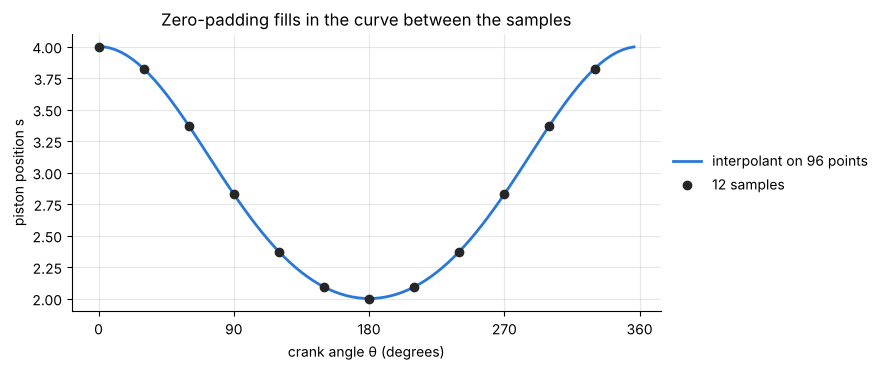

In [15]:
N, M = 12, 96
x, x_fine = 2 * np.pi * np.arange(N) / N, 2 * np.pi * np.arange(M) / M
band_limited = lambda x: 1 + np.cos(3 * x) - 2 * np.sin(5 * x) + 0.5 * np.cos(6 * x)
assert np.abs(fourier_interpolate(band_limited(x), M) - band_limited(x_fine)).max() < 1e-13

interpolation_error = np.abs(fourier_interpolate(position(x), M) - position(x_fine)).max()
print(f"piston position from {N} samples, evaluated at {M} angles: largest error {interpolation_error:.1e}")
assert interpolation_error < 1e-6

fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.plot(np.degrees(x_fine), fourier_interpolate(position(x), M), label="interpolant on 96 points")
ax.plot(np.degrees(x), position(x), "o", color="0.15", ms=6, label="12 samples")
ax.set(xlabel="crank angle θ (degrees)", ylabel="piston position s", xticks=[0, 90, 180, 270, 360],
       title="Zero-padding fills in the curve between the samples")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

Twelve samples per revolution define the piston position everywhere to better than $10^{-6}$.
This is how a smooth curve is drawn through coarse spectral data, and how a quantity such as
the crank angle of greatest piston speed is located more finely than the grid spacing.

## 2.9 Worked example: differentiating measured data

**Problem.** The piston position is now **measured**, at $N = 256$ crank angles by a sensor
whose errors are random with standard deviation $\sigma = 10^{-6}$ (one part in a million of
the crank radius, a very good sensor). Find the acceleration $d^2s/d\theta^2$.

**By hand.** Differentiating twice multiplies the amplitude at wavenumber $k$ by $-k^2$. The
signal does not mind, because its amplitudes decay rapidly with $k$. Random noise does not
decay: it puts about the same energy into every wavenumber, up to $k = N/2 = 128$, where it is
multiplied by $128^2 \approx 16\,000$. By Parseval's identity the root-mean-square error of the
computed acceleration should be

$$\sigma\,\Big(\frac1N\sum_k k^4\Big)^{1/2} \approx \frac{\sigma}{\sqrt5}\Big(\frac N2\Big)^2 \approx 7\times10^{-3} ,$$

seven thousand times the measurement error.

In [16]:
N, sigma = 256, 1e-6
theta = 2 * np.pi * np.arange(N) / N
k = np.fft.fftfreq(N, 1 / N)
measured = position(theta) + sigma * np.random.default_rng(0).standard_normal(N)

raw = fft_derivative(measured, 2)
raw_rms = np.sqrt(np.mean((raw - acceleration(theta)) ** 2))
predicted_rms = sigma * np.sqrt(np.mean(k**4))
print(f"rms error of the acceleration: {raw_rms:.2e}   predicted from the noise level: {predicted_rms:.2e}")
assert 0.8 < raw_rms / predicted_rms < 1.25

rms error of the acceleration: 7.38e-03   predicted from the noise level: 7.33e-03


The prediction holds. The cure follows from the same picture. Look at the amplitudes of the
measured data: the signal falls geometrically until it meets the flat **noise floor**, at
about $\sigma/\sqrt N$, and beyond that point the data contain nothing but noise. So keep the
wavenumbers on the signal side of the crossing and set the rest to zero: a **low-pass filter**.

In [17]:
def low_pass(v, cutoff):
    """Remove all wavenumbers above the cut-off from the periodic samples v."""
    v_hat = np.fft.fft(v)
    v_hat[np.abs(np.fft.fftfreq(len(v), 1 / len(v))) > cutoff] = 0
    return np.real(np.fft.ifft(v_hat))

amplitude_clean = np.abs(np.fft.fft(position(theta))) / N
amplitude_measured = np.abs(np.fft.fft(measured)) / N
above_floor = np.flatnonzero(amplitude_clean[: N // 2] > sigma / np.sqrt(N))
cutoff = int(above_floor.max())
print("wavenumbers at which the exact signal is above the noise floor:", above_floor, " -> cut-off", cutoff)

filtered = fft_derivative(low_pass(measured, cutoff), 2)
raw_error, filtered_error = np.abs(raw - acceleration(theta)).max(), np.abs(filtered - acceleration(theta)).max()
print(f"largest error in the acceleration: unfiltered {raw_error:.1e}, filtered {filtered_error:.1e}, "
      f"improvement {raw_error / filtered_error:.0f} times")
assert cutoff == 8 and filtered_error < 1e-4 and raw_error > 500 * filtered_error

wavenumbers at which the exact signal is above the noise floor: [0 1 2 4 6 8]  -> cut-off 8
largest error in the acceleration: unfiltered 2.0e-02, filtered 1.7e-05, improvement 1193 times


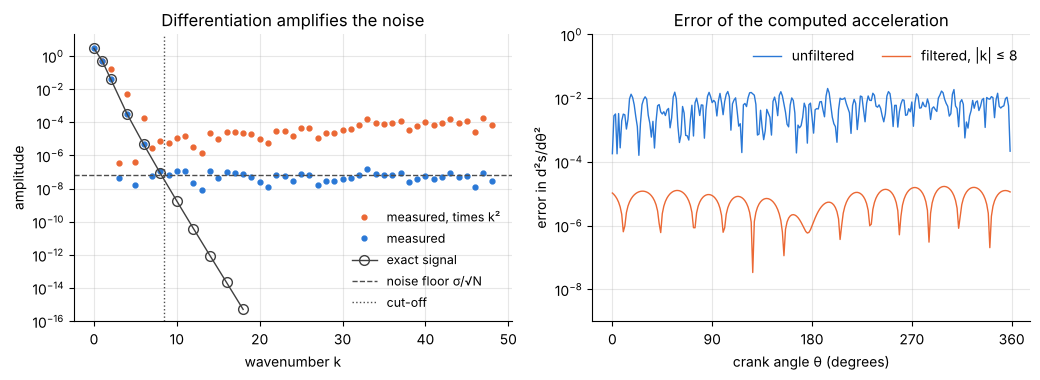

In [18]:
shown = np.arange(49)
present = shown[amplitude_clean[shown] > 1e-16]               # the odd wavenumbers above 1 are absent from the exact signal
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].semilogy(shown[1:], shown[1:] ** 2 * amplitude_measured[shown[1:]], "o", ms=3.5, color="C1", label="measured, times k²")
axes[0].semilogy(shown, amplitude_measured[shown], "o", ms=3.5, color="C0", label="measured")
axes[0].semilogy(present, amplitude_clean[present], "o-", ms=7, lw=1, mfc="none", color="0.25", label="exact signal")
axes[0].axhline(sigma / np.sqrt(N), color="0.3", lw=1, ls="--", label="noise floor σ/√N")
axes[0].axvline(cutoff + 0.5, color="0.3", lw=1, ls=":", label="cut-off")
axes[0].set(xlabel="wavenumber k", ylabel="amplitude", ylim=(1e-16, 20), title="Differentiation amplifies the noise")
axes[0].legend(frameon=False, loc="lower right", fontsize=9)
axes[1].semilogy(np.degrees(theta), np.abs(raw - acceleration(theta)), lw=1, label="unfiltered")
axes[1].semilogy(np.degrees(theta), np.abs(filtered - acceleration(theta)), lw=1, label=f"filtered, |k| ≤ {cutoff}")
axes[1].set(xlabel="crank angle θ (degrees)", ylabel="error in d²s/dθ²", xticks=[0, 90, 180, 270, 360],
            ylim=(1e-9, 1), title="Error of the computed acceleration")
axes[1].legend(frameon=False, loc="upper right", ncol=2)
fig.tight_layout()

The left panel shows wavenumbers 0 to 48 of the 128. The measured amplitudes follow the
exact ones down to the noise floor, which they reach near $k = 8$, and stay there. (Odd
wavenumbers above 1 are absent from the exact signal because the square-root term repeats
twice per revolution.) Multiplying by $k^2$ turns the flat floor into a rising curve that
overtakes the signal. Keeping only $|k| \le 8$ improves the acceleration by three orders of
magnitude.

What this means in practice: spectral differentiation is exact for the interpolant, noise
included. With measured data, or data computed elsewhere to limited accuracy, look at the
spectrum before differentiating. The place where it stops decaying tells you both how much of
the data is signal and where to cut. Here the cut-off came from the exact signal; with real
measurements it is read off the left panel by eye. The filter works because the piston motion
is smooth. A signal with sharp features has a slowly decaying spectrum, the crossing moves to
high $k$, and less can be saved (notebook 3).

## Summary

- On $N$ points, wavenumbers that differ by $N$ are indistinguishable (aliasing). The grid
  carries the wavenumbers up to $N/2$: two points per wavelength.
- Differentiating the band-limited interpolant of the data gives the spectral differentiation
  matrix. On an unbounded grid its entries are the infinite-order finite difference weights of
  notebook 1, on the periodic grid the cotangent formula.
- The same derivative is computed by the FFT: transform, multiply by $(ik)^m$, transform back.
  The cost is $O(N\log N)$ against $O(N^2)$.
- The second-derivative matrix $D^{(2)}$ keeps the Nyquist mode, so it is not $D^2$.
- For odd derivatives set the Nyquist mode to zero. `np.fft.fftfreq(N, 1/N)` gives the
  wavenumber ordering.
- Zero-padding in Fourier space evaluates the interpolant between the grid points.
- Differentiation amplifies noise by $k^m$. Inspect the spectrum, and filter if the data are noisy.

`fourier_diff_matrix(N)`, `fourier_diff2_matrix(N)` and `fft_derivative(v, order)` are used
unchanged in later notebooks.

## Exercises

1. For $u(x) = e^{\sin x}$ the third derivative is
   $u''' = (\cos^3x - 3\sin x\cos x - \cos x)\,e^{\sin x}$. Compute it with
   `fft_derivative(u, 3)` for $N = 8, 16, 24, 32$ and tabulate the largest error. Then compute it
   as `D @ D @ D @ u` with `fourier_diff_matrix` and confirm that the two results agree to
   rounding for $N = 32$.
2. For $N = 16$ compare the second-derivative matrix $D^{(2)}$, `fourier_diff2_matrix(N)`, with
   the square of the first-derivative matrix, `D @ D`. Show that the difference
   $D^{(2)} - D^2$ is a multiple of the matrix with entries $(-1)^{i+j}$, find the multiple, and
   explain the result with the Nyquist mode.
3. Sample $u(x) = \sin 13x$ on the grid with $N = 16$. Which wavenumber between $-7$ and $8$
   has the same samples? Compute `fft_derivative(u)` and compare it with the exact derivative
   $13\cos 13x$ at the grid points. What is the largest error, and why is it exactly that number?
4. The piston of this notebook ($r = 1$, $l = 3$) is sampled at $N = 32$ crank angles. Find the
   crank angle between $0$ and $180^\circ$ at which the piston speed $|ds/d\theta|$ is greatest,
   using `fft_derivative` and then `fourier_interpolate` with $M = 4096$. Compare with the exact
   angle, which is the root of the exact acceleration (use `scipy.optimize.brentq` on
   `acceleration` between $1$ and $2$ radians). How does the error compare with the spacing of
   the fine grid?
5. Repeat the noisy-data example of 2.9 with a poorer sensor, $\sigma = 10^{-4}$, $N = 256$ and
   `np.random.default_rng(1)`. Compute the largest error of the filtered acceleration for
   every cut-off from 2 to 12 and report the best cut-off. Is it the one suggested by the noise
   floor $\sigma/\sqrt N$? Then do the same for the velocity (first derivative): how much does
   filtering help there, and why less?